In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from coffea import util
from coffea.processor import accumulate
import os
import re
import pandas as pd
import hist
import matplotlib as mpl
import mplhep
import sys
import hist
import hist.intervals


sys.path.append("/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/analysisTools")
import plotTools as ptools
import utils

In [2]:
f_sig = "/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/AllInOne_2022/Res_LR_lxy.coffea"

sig_histo = util.load(f_sig) [0]

sum_counts= [[6.7680e+03 2.6560e+03 9.5000e+01 9.0000e+00 3.0000e+00]
 [2.7430e+04 1.5231e+04 9.7700e+02 7.8000e+01 2.1000e+01]
 [4.3635e+04 4.7317e+04 6.8740e+03 6.4500e+02 1.8800e+02]
 [1.5636e+04 2.8207e+04 5.6850e+03 5.4500e+02 1.7000e+02]]
sum_edges_pt= [ 0.  5. 10. 20. 30.]
sum_edges_vxy= [ 0.  1.  5. 10. 15. 20.]


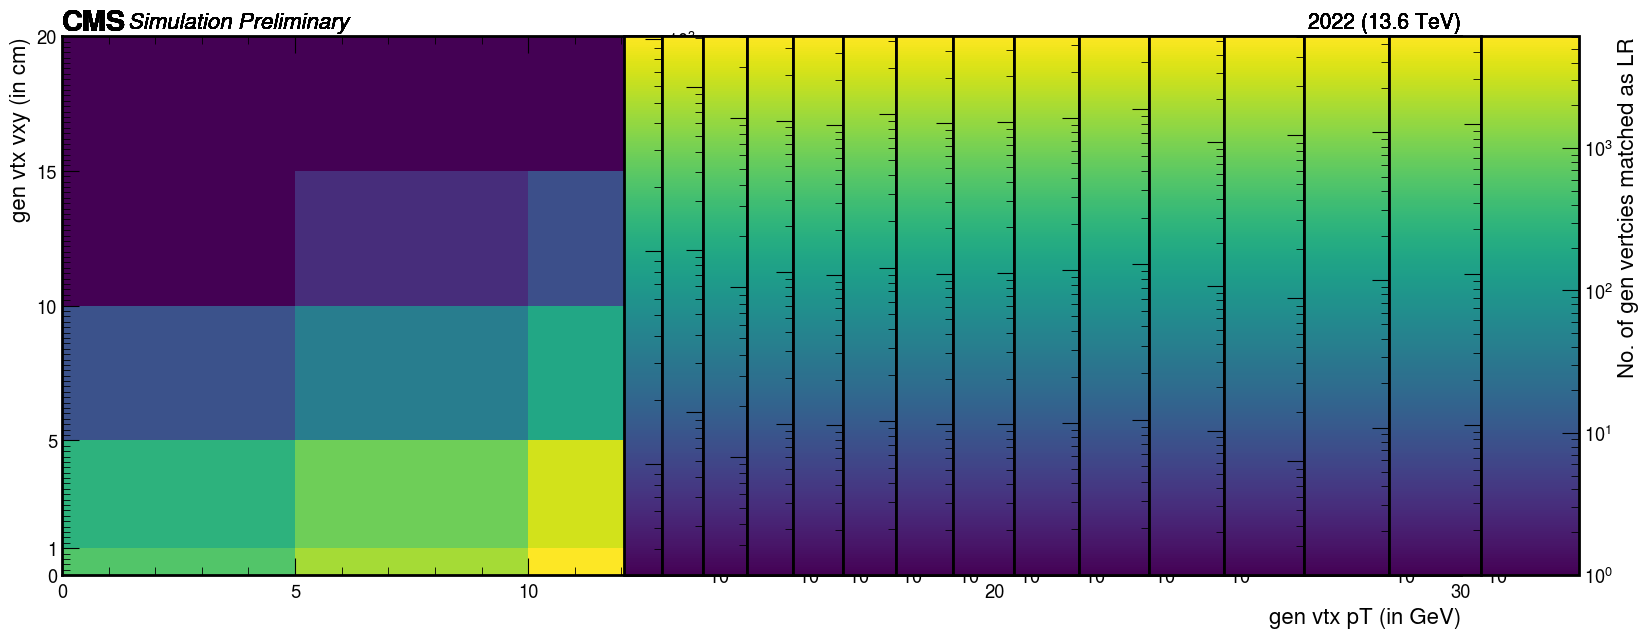

In [3]:
fig, ax = plt.subplots(figsize=(7,7))

#Numerator: No. of gen vertices matched as LL

# Plot settings
plot_dict = {
    'variable':'genvtx_pt_vxy',
    'cut': 'cut1',
    'year': 2022
}

style_2d_dict = {
    'fig': fig,
    'ax': ax,
    'xrebin': None,
    'yrebin': None,
    'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]  
    'ylim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
    'doLogy': False, 
    'doLogx': False,
    'doLogz': True,
    'xlabel': "gen vtx pT (in GeV)",   # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
    'ylabel': "gen vtx vxy (in cm)",   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
    'zlabel': "No. of gen vertcies matched as LR",   
    'flow': None,     # overflow
    'doSave': False,
    'outDir': './plots/signal_2018',
    'outName': f'ptvslxy.png'
}

#signal points
samples = {
    10: 
    {
        
        0.2: [100],
    },
    20: 
    {
        
        0.2: [100],
        
    },
    30: 
    {
       
        0.2: [100]
    },
    40: 
    {
        0.2: [100],
    },
    50:
    {
        
        0.2: [100],
    },
    60:
    {
        
         0.1: [100],
         0.2: [100]
    
    },
    70:
    {    0.1: [100],
         0.2: [100],
    },
    80:
    {    0.1: [100],
         0.2: [100],
    },
    90:
    {    0.1: [100],
         0.2: [100],
    },
    100:
    {    0.1: [100],
         0.2: [100],
    }
}


h_list_lpt=[]
h_sum_lpt = None

sum_counts = None
sum_edges_pt = None
sum_edges_vxy = None

for m1,deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            h_lpt = ptools.plot_signal_2D(sig_histo, m1, delta, ctau, plot_dict, style_2d_dict)
            counts_i = np.asarray(h_lpt[0], dtype=float) 
            edges_pt = np.asarray(h_lpt[1], dtype=float)
            edges_vxy = np.asarray(h_lpt[2], dtype=float)
            h_list_lpt.append((counts_i, edges_pt, edges_vxy))
            if sum_counts is None: 
                sum_counts = counts_i.copy() 
                sum_edges_pt = edges_pt.copy() 
                sum_edges_vxy = edges_vxy.copy()
            else: 
                sum_counts += counts_i
            
print ("sum_counts=", sum_counts)
print ("sum_edges_pt=", sum_edges_pt)
print ("sum_edges_vxy=", sum_edges_vxy)


In [4]:
RR_counts = np.array([
    [5.1360e+03, 1.1600e+03, 2.5000e+01, 1.0000e+00, 0.0000e+00],
 [2.3461e+04, 6.6060e+03, 1.6600e+02, 4.0000e+00, 2.0000e+00],
 [6.7568e+04, 3.7730e+04, 1.7700e+03, 3.7000e+01, 9.0000e+00],
 [3.2795e+04, 2.8171e+04, 1.7770e+03, 3.5000e+01, 5.0000e+00]
    
])

LL_counts = np.array([
    [1.1084e+04, 7.6790e+03, 8.0000e+02, 1.0700e+02, 2.0000e+01],
 [3.0121e+04, 3.3221e+04, 7.0800e+03, 1.6150e+03, 4.3900e+02],
 [3.8072e+04, 7.4819e+04, 3.6508e+04, 1.3274e+04, 5.6690e+03],
 [1.6493e+04, 4.1661e+04, 3.1110e+04, 1.4413e+04, 7.4540e+03]    
                     ])



BIG_COUNTS = sum_counts+LL_counts+RR_counts
print (BIG_COUNTS)

[[2.29880e+04 1.14950e+04 9.20000e+02 1.17000e+02 2.30000e+01]
 [8.10120e+04 5.50580e+04 8.22300e+03 1.69700e+03 4.62000e+02]
 [1.49275e+05 1.59866e+05 4.51520e+04 1.39560e+04 5.86600e+03]
 [6.49240e+04 9.80390e+04 3.85720e+04 1.49930e+04 7.62900e+03]]


sum_counts_den= [[ 503929. 1162701.  717099.  398744.  245197.]
 [ 700169. 1602467.  992198.  551334.  341502.]
 [ 616294. 1646365. 1189052.  733741.  484119.]
 [ 169640.  535063.  446211.  299735.  207255.]]
sum_edges_pt_den= [ 0.  5. 10. 20. 30.]
sum_edges_vxy_den= [ 0.  1.  5. 10. 15. 20.]


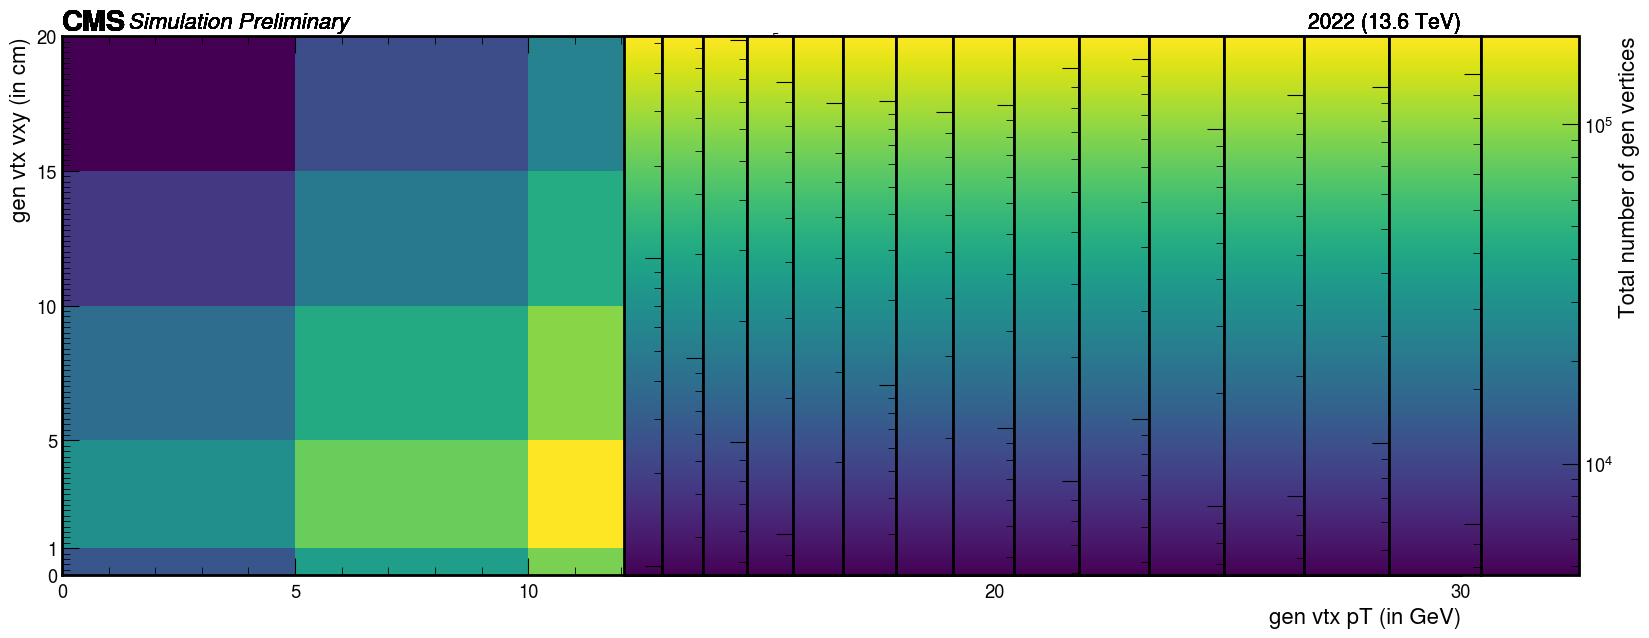

In [5]:
fig, ax = plt.subplots(figsize=(7,7))


# Plot settings
plot_dict = {
    'variable':'genvtx_pt_vxy_den',
    'cut': 'cut1',
    'year': 2022
}

style_2d_dict = {
    'fig': fig,
    'ax': ax,
    'xrebin': None,
    'yrebin': None,
    'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]  
    'ylim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
    'doLogy': False, 
    'doLogx': False,
    'doLogz': True,
    'xlabel': "gen vtx pT (in GeV)",   # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
    'ylabel': "gen vtx vxy (in cm)",   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
    'zlabel': "Total number of gen vertices",   
    'flow': None,     # overflow
    'doSave': False,
    'outDir': './plots/signal_2018',
    'outName': f'ptvslxy.png'
}

#signal points
samples = {
    10: 
    {
        
        0.2: [100],
    },
    20: 
    {
        
        0.2: [100],
        
    },
    30: 
    {
       
        0.2: [100]
    },
    40: 
    {
        0.2: [100],
    },
    50:
    {
        
        0.2: [100],
    },
    60:
    {
        
         0.1: [100],
         0.2: [100]
    
    },
    70:
    {    0.1: [100],
         0.2: [100],
    },
    80:
    {    0.1: [100],
         0.2: [100],
    },
    90:
    {    0.1: [100],
         0.2: [100],
    },
    100:
    {    0.1: [100],
         0.2: [100],
    }
}


h_list_lpt_den=[]
h_sum_lpt_den = None

sum_counts_den = None
sum_edges_pt_den = None
sum_edges_vxy_den = None

for m1,deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            h_lpt_den = ptools.plot_signal_2D(sig_histo, m1, delta, ctau, plot_dict, style_2d_dict)
            counts_i_den = np.asarray(h_lpt_den[0], dtype=float) 
            edges_pt_den = np.asarray(h_lpt_den[1], dtype=float)
            edges_vxy_den = np.asarray(h_lpt_den[2], dtype=float)
            h_list_lpt_den.append((counts_i_den, edges_pt_den, edges_vxy_den))
            if sum_counts_den is None: 
                sum_counts_den = counts_i_den.copy() 
                sum_edges_pt_den = edges_pt_den.copy() 
                sum_edges_vxy_den = edges_vxy_den.copy()
            else: 
                sum_counts_den += counts_i_den
            
print ("sum_counts_den=", sum_counts_den)
print ("sum_edges_pt_den=", sum_edges_pt_den)
print ("sum_edges_vxy_den=", sum_edges_vxy_den)


In [6]:
def eff_determine_unc(n, d):
    eff = np.divide(n, d)
    unc = hist.intervals.ratio_uncertainty(n, d, 'efficiency')
    return eff, unc


efficiency_lpt, unc_lpt = eff_determine_unc(sum_counts, sum_counts_den)
print ("efficiency_lpt=", efficiency_lpt)
print ("unc_lpt=", unc_lpt)

efficiency_lpt= [[1.34304634e-02 2.28433621e-03 1.32478221e-04 2.25708725e-05
  1.22350600e-05]
 [3.91762560e-02 9.50471991e-03 9.84682493e-04 1.41475041e-04
  6.14930513e-05]
 [7.08022470e-02 2.87402854e-02 5.78107602e-03 8.79056779e-04
  3.88334273e-04]
 [9.21716576e-02 5.27171567e-02 1.27406093e-02 1.81827281e-03
  8.20245591e-04]]
unc_lpt= [[[1.62175379e-04 4.42732285e-05 1.35672939e-05 7.38179453e-06
   6.65873939e-06]
  [2.31917616e-04 7.66531553e-05 3.14828672e-05 1.59835924e-05
   1.33109662e-05]
  [3.26839331e-04 1.30228706e-04 6.95287754e-05 3.45898284e-05
   2.82922718e-05]
  [7.02856174e-04 3.05597957e-04 1.67919537e-04 7.77974999e-05
   6.28260904e-05]]

 [[1.64118300e-04 4.51376851e-05 1.50331073e-05 1.03077076e-05
   1.19012493e-05]
  [2.33237991e-04 7.72678229e-05 3.25048573e-05 1.78997565e-05
   1.65590868e-05]
  [3.28235623e-04 1.30802526e-04 7.03650867e-05 3.59771339e-05
   3.04316826e-05]
  [7.07684501e-04 3.07274958e-04 1.70118102e-04 8.11929800e-05
   6.78282634e-

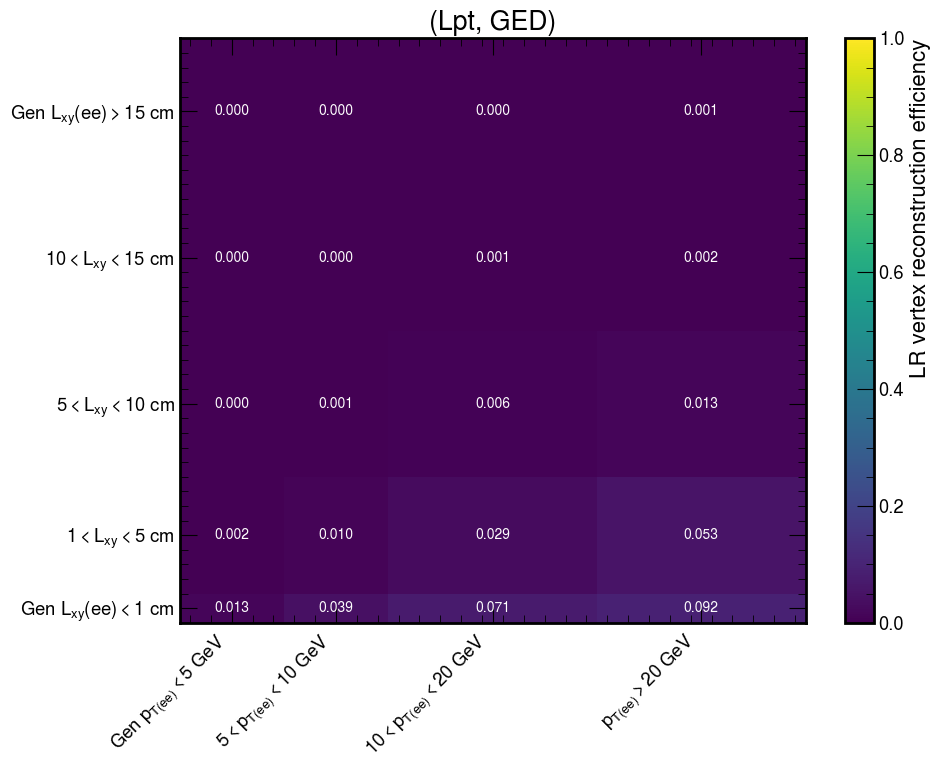

In [7]:
# Calculate the 2D efficiency safely
efficiency_lpt = np.divide(
    sum_counts,
    sum_counts_den,
    out=np.full_like(sum_counts, np.nan, dtype=float),
    where=(sum_counts_den > 0)
)

efficiency_to_plot = efficiency_lpt.T

fig, ax = plt.subplots(figsize=(10, 8))

mesh = ax.pcolormesh(
    sum_edges_pt,
    sum_edges_vxy,
    efficiency_to_plot,
    cmap="viridis",
    shading="auto",
    vmin=0,
    vmax=1
)

cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("LR vertex reconstruction efficiency")

# Calculate bin centers
pt_centers = 0.5 * (sum_edges_pt[:-1] + sum_edges_pt[1:])
vxy_centers = 0.5 * (sum_edges_vxy[:-1] + sum_edges_vxy[1:])

# Add efficiency values inside the boxes
for vxy_index, vxy_center in enumerate(vxy_centers):
    for pt_index, pt_center in enumerate(pt_centers):

        efficiency = efficiency_to_plot[vxy_index, pt_index]

        # Leave bins with no denominator events blank
        if np.isnan(efficiency):
            continue

        text_color = "white" if efficiency < 0.5 else "black"

        ax.text(
            pt_center,
            vxy_center,
            f"{efficiency:.3f}",
            # f"{100 * efficiency:.2f}%",
            ha="center",
            va="center",
            color=text_color,
            fontsize=10
        )

# Create x-axis labels automatically from the actual pT edges
x_labels = []

for index in range(len(pt_centers)):
    low_edge = sum_edges_pt[index]
    high_edge = sum_edges_pt[index + 1]

    if index == 0:
        label = rf"Gen $p_{{\mathrm{{T}}(ee)}} < {high_edge:g}$ GeV"
    elif index == len(pt_centers) - 1:
        label = rf"$p_{{\mathrm{{T}}(ee)}} > {low_edge:g}$ GeV"
    else:
        label = (
            rf"${low_edge:g} < p_{{\mathrm{{T}}(ee)}}"
            rf" < {high_edge:g}$ GeV"
        )

    x_labels.append(label)

# Create y-axis labels automatically from the actual vxy edges
y_labels = []

for index in range(len(vxy_centers)):
    low_edge = sum_edges_vxy[index]
    high_edge = sum_edges_vxy[index + 1]

    if index == 0:
        label = rf"Gen $L_{{xy}}(ee) < {high_edge:g}$ cm"
    elif index == len(vxy_centers) - 1:
        label = rf"Gen $L_{{xy}}(ee) > {low_edge:g}$ cm"
    else:
        label = rf"${low_edge:g} < L_{{xy}} < {high_edge:g}$ cm"

    y_labels.append(label)

# Set custom tick positions and labels
ax.set_xticks(pt_centers)
ax.set_xticklabels(
    x_labels,
    rotation=45,
    ha="right"
)

ax.set_yticks(vxy_centers)
ax.set_yticklabels(y_labels)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("(Lpt, GED)")

plt.tight_layout()
plt.show()

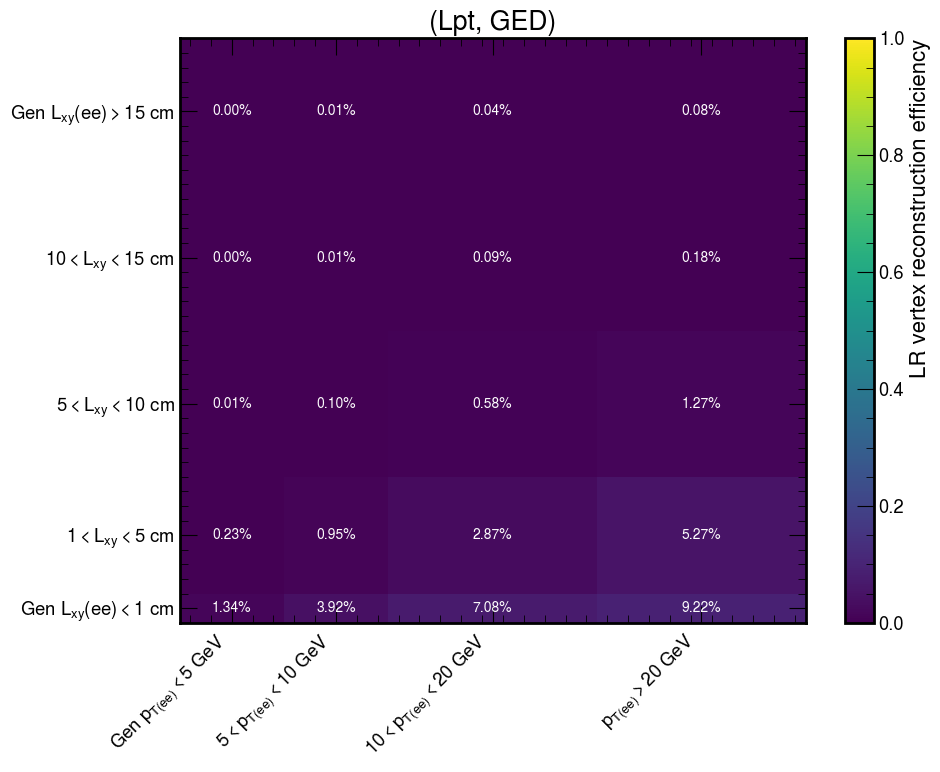

In [8]:
# Calculate the 2D efficiency safely
efficiency_lpt = np.divide(
    sum_counts,
    sum_counts_den,
    out=np.full_like(sum_counts, np.nan, dtype=float),
    where=(sum_counts_den > 0)
)

efficiency_to_plot = efficiency_lpt.T

fig, ax = plt.subplots(figsize=(10, 8))

mesh = ax.pcolormesh(
    sum_edges_pt,
    sum_edges_vxy,
    efficiency_to_plot,
    cmap="viridis",
    shading="auto",
    vmin=0,
    vmax=1
)

cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("LR vertex reconstruction efficiency")

# Calculate bin centers
pt_centers = 0.5 * (sum_edges_pt[:-1] + sum_edges_pt[1:])
vxy_centers = 0.5 * (sum_edges_vxy[:-1] + sum_edges_vxy[1:])

# Add efficiency values inside the boxes
for vxy_index, vxy_center in enumerate(vxy_centers):
    for pt_index, pt_center in enumerate(pt_centers):

        efficiency = efficiency_to_plot[vxy_index, pt_index]

        # Leave bins with no denominator events blank
        if np.isnan(efficiency):
            continue

        text_color = "white" if efficiency < 0.5 else "black"

        ax.text(
            pt_center,
            vxy_center,
            # f"{efficiency:.2f}",
            f"{100 * efficiency:.2f}%",
            ha="center",
            va="center",
            color=text_color,
            fontsize=10
        )

# Create x-axis labels automatically from the actual pT edges
x_labels = []

for index in range(len(pt_centers)):
    low_edge = sum_edges_pt[index]
    high_edge = sum_edges_pt[index + 1]

    if index == 0:
        label = rf"Gen $p_{{\mathrm{{T}}(ee)}} < {high_edge:g}$ GeV"
    elif index == len(pt_centers) - 1:
        label = rf"$p_{{\mathrm{{T}}(ee)}} > {low_edge:g}$ GeV"
    else:
        label = (
            rf"${low_edge:g} < p_{{\mathrm{{T}}(ee)}}"
            rf" < {high_edge:g}$ GeV"
        )

    x_labels.append(label)

# Create y-axis labels automatically from the actual vxy edges
y_labels = []

for index in range(len(vxy_centers)):
    low_edge = sum_edges_vxy[index]
    high_edge = sum_edges_vxy[index + 1]

    if index == 0:
        label = rf"Gen $L_{{xy}}(ee) < {high_edge:g}$ cm"
    elif index == len(vxy_centers) - 1:
        label = rf"Gen $L_{{xy}}(ee) > {low_edge:g}$ cm"
    else:
        label = rf"${low_edge:g} < L_{{xy}} < {high_edge:g}$ cm"

    y_labels.append(label)

# Set custom tick positions and labels
ax.set_xticks(pt_centers)
ax.set_xticklabels(
    x_labels,
    rotation=45,
    ha="right"
)

ax.set_yticks(vxy_centers)
ax.set_yticklabels(y_labels)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("(Lpt, GED)")

plt.tight_layout()
plt.show()

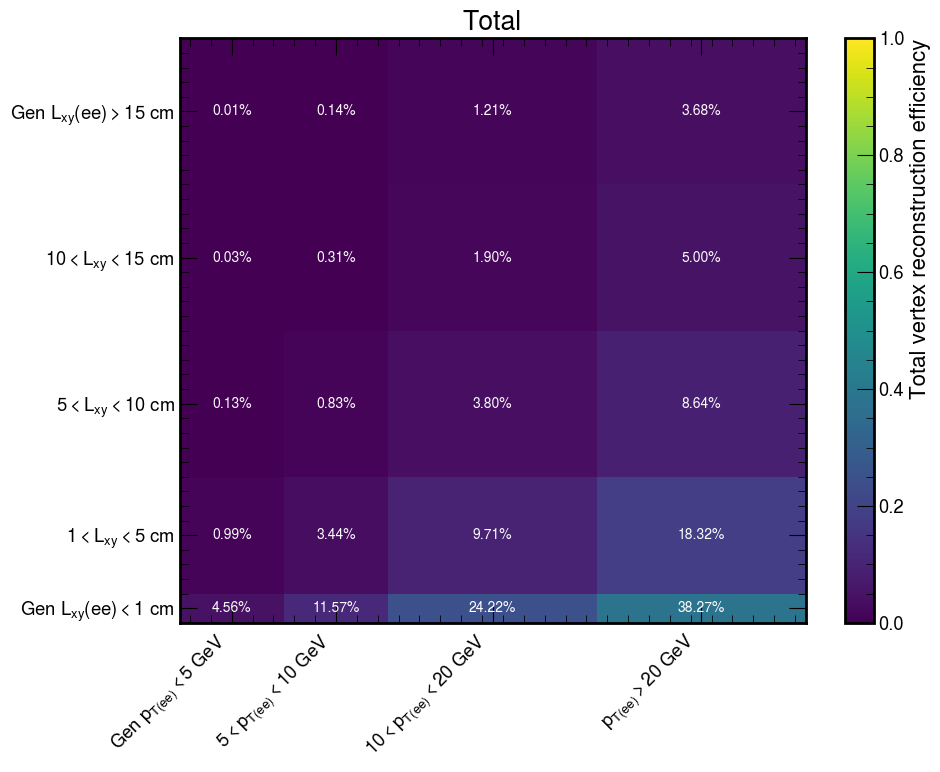

In [9]:
# Calculate the 2D efficiency safely
efficiency_lpt = np.divide(
    BIG_COUNTS,
    sum_counts_den,
    out=np.full_like(BIG_COUNTS, np.nan, dtype=float),
    where=(sum_counts_den > 0)
)

efficiency_to_plot = efficiency_lpt.T

fig, ax = plt.subplots(figsize=(10, 8))

mesh = ax.pcolormesh(
    sum_edges_pt,
    sum_edges_vxy,
    efficiency_to_plot,
    cmap="viridis",
    shading="auto",
    vmin=0,
    vmax=1
)

cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("Total vertex reconstruction efficiency")

# Calculate bin centers
pt_centers = 0.5 * (sum_edges_pt[:-1] + sum_edges_pt[1:])
vxy_centers = 0.5 * (sum_edges_vxy[:-1] + sum_edges_vxy[1:])

# Add efficiency values inside the boxes
for vxy_index, vxy_center in enumerate(vxy_centers):
    for pt_index, pt_center in enumerate(pt_centers):

        efficiency = efficiency_to_plot[vxy_index, pt_index]

        # Leave bins with no denominator events blank
        if np.isnan(efficiency):
            continue

        text_color = "white" if efficiency < 0.5 else "black"

        ax.text(
            pt_center,
            vxy_center,
            # f"{efficiency:.2f}",
            f"{100 * efficiency:.2f}%",
            ha="center",
            va="center",
            color=text_color,
            fontsize=10
        )

# Create x-axis labels automatically from the actual pT edges
x_labels = []

for index in range(len(pt_centers)):
    low_edge = sum_edges_pt[index]
    high_edge = sum_edges_pt[index + 1]

    if index == 0:
        label = rf"Gen $p_{{\mathrm{{T}}(ee)}} < {high_edge:g}$ GeV"
    elif index == len(pt_centers) - 1:
        label = rf"$p_{{\mathrm{{T}}(ee)}} > {low_edge:g}$ GeV"
    else:
        label = (
            rf"${low_edge:g} < p_{{\mathrm{{T}}(ee)}}"
            rf" < {high_edge:g}$ GeV"
        )

    x_labels.append(label)

# Create y-axis labels automatically from the actual vxy edges
y_labels = []

for index in range(len(vxy_centers)):
    low_edge = sum_edges_vxy[index]
    high_edge = sum_edges_vxy[index + 1]

    if index == 0:
        label = rf"Gen $L_{{xy}}(ee) < {high_edge:g}$ cm"
    elif index == len(vxy_centers) - 1:
        label = rf"Gen $L_{{xy}}(ee) > {low_edge:g}$ cm"
    else:
        label = rf"${low_edge:g} < L_{{xy}} < {high_edge:g}$ cm"

    y_labels.append(label)

# Set custom tick positions and labels
ax.set_xticks(pt_centers)
ax.set_xticklabels(
    x_labels,
    rotation=45,
    ha="right"
)

ax.set_yticks(vxy_centers)
ax.set_yticklabels(y_labels)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Total")

plt.tight_layout()
plt.show()